# 建模&结果


## 1. 构造历史特征
按站点计算滞后和滚动均值，滚动窗口只使用过去观测。8 月 1–7 日提供历史（因为需要用到前七天的数据），训练期为 8 月 8 日至 9 月 30 日，验证期为 10 月 1–15 日。
本项目使用特征：
站点与时间特征	站点 ID、一天中的小时（0–23）、星期几
短期滞后	同站点 1、2、3、6 小时前的需求量
日与周滞后	同站点 24、168 小时前的需求量（一天、一周）
滚动均值	同站点过去 24、168 小时的平均需求量
departures (11 features)：station_id, hour_of_day, day_of_week, departures_lag_1, departures_lag_24, departures_lag_168, departures_rolling_mean_24, departures_rolling_mean_168, departures_lag_2, departures_lag_3, departures_lag_6
arrivals (11 features): station_id, hour_of_day, day_of_week, arrivals_lag_1, arrivals_lag_24, arrivals_lag_168, arrivals_rolling_mean_24, arrivals_rolling_mean_168, arrivals_lag_2, arrivals_lag_3, arrivals_lag_6

In [1]:
# 从上到下运行四个代码单元。后面的模型和图表使用前面生成的变量。
import sys
from pathlib import Path
import pandas as pd

project = Path(r"E:\5206\group project")
# 把该目录加入模块搜索路径，下面的 import 才能找到参考代码。
sys.path.insert(0, str(project))
from features import create_demand_features, remove_incomplete_history
from models import get_model_features

# 站点编号只是类别标识。读成字符串，避免模型把编号的大小当作数值规律。
raw = pd.read_excel(project / "data.xlsx", dtype={"station_id": str})
raw["hour"] = pd.to_datetime(raw["hour"])
# 先排除 10 月 16 日及以后，再按站点和时间排序。测试期尚未参与建模。
history = raw.loc[raw.hour.lt("2026-10-16")].sort_values(["station_id", "hour"])
# 同一站点相邻记录必须恰好相隔一小时，否则 shift(24) 可能并不代表 24 小时前。
assert history.groupby("station_id").hour.diff().dropna().eq(pd.Timedelta(hours=1)).all()
# 参考函数构造小时、星期、1/24/168 小时滞后与 24/168 小时滚动均值。
# 滚动均值先 shift(1) 再取窗口，因此预测 10 点时不会用到 10 点的真实需求。
features = create_demand_features(history)
# 增加同站、同目标的 2、3、6 小时滞后，描述最近几个小时的需求。
extra_lags = [2, 3, 6]
for target in ("departures", "arrivals"):
    # 借车特征用历史借车量，还车特征用历史还车量。groupby 避免跨站取值。
    grouped = features.groupby("station_id")[target]
    for lag in extra_lags:
        # shift(lag) 取同站往前第 lag 行的需求，例如 lag=2 表示 8 点的值用于 10 点。
        features[f"{target}_lag_{lag}"] = grouped.shift(lag)
# 前 168 小时缺少完整历史，只用于生成后面的特征。
features = remove_incomplete_history(features)
# 8 月 8 日至 9 月 30 日训练，10 月 1–15 日验证。先构造特征再切分，
# 这样 10 月 1 日的预测仍可用 9 月底的历史。逐小时预测时也可用已观测的验证期历史。
train = features.loc[features.hour.lt("2026-10-01")]
validation = features.loc[features.hour.ge("2026-10-01")]
# 核对两个时间段的站点小时数。20 个站点乘以各自的小时数。
assert (len(train), len(validation)) == (25920, 7200)
print(f"Training: {len(train):,} | Validation: {len(validation):,}")


Training: 25,920 | Validation: 7,200


## 2. 确认建模列
分别列出借车与还车的 11 个输入特征，并检查缺失值。后续模型需要使用这里定义的 `feature_columns`。

In [2]:
# 用字典保存两个目标各自的输入列清单。目标本身和当前净流量都不作为输入。
feature_columns = {}
for target in ("departures", "arrivals"):
    # 前三列是站点、小时和星期类别。其余是该目标的历史数值特征。
    categorical, numerical = get_model_features(target)
    feature_columns[target] = list(categorical) + list(numerical) + [
        f"{target}_lag_{lag}" for lag in extra_lags
    ]
    columns = feature_columns[target]
    # 去除历史不足的行后，训练和验证特征应齐全。发现缺失就停止，避免把问题带入模型。
    assert not features[columns].isna().any().any()
    print(f"{target} ({len(columns)} features): {', '.join(columns)}")


departures (11 features): station_id, hour_of_day, day_of_week, departures_lag_1, departures_lag_24, departures_lag_168, departures_rolling_mean_24, departures_rolling_mean_168, departures_lag_2, departures_lag_3, departures_lag_6
arrivals (11 features): station_id, hour_of_day, day_of_week, arrivals_lag_1, arrivals_lag_24, arrivals_lag_168, arrivals_rolling_mean_24, arrivals_rolling_mean_168, arrivals_lag_2, arrivals_lag_3, arrivals_lag_6


## 3. 模型训练与验证
三个模型：周季节基线使用同一站点上周同小时的实际需求（作为基础对比）；Poisson 回归；随机森林。分别为借车、还车拟合模型，均使用上一节确定的 11 个输入特征。只用 8 月 8 日至 9 月 30 日拟合，在 10 月 1–15 日逐小时验证。以 MAE 排序，RMSE 和 WAPE（百分比）作为补充。

In [3]:
from IPython.display import display
from models import build_poisson_model, build_random_forest_model, seasonal_naive_predictions
from evaluate import evaluate_forecast

# 周季节基线直接用同站上周同一小时的实际量，因此没有拟合步骤。
baseline = seasonal_naive_predictions(validation)
# 保存两个模型的构造函数。每次调用都会为当前目标创建新的模型。
builders = {"Poisson": build_poisson_model, "Random Forest": build_random_forest_model}
# 按 (预测目标, 模型名称) 存储拟合结果，供画图时取用。
fitted_models = {}
scores = []

for target, columns in feature_columns.items():
    # y 是要预测的真实借车量或还车量。训练目标用于拟合，验证目标用于评分。
    y_train = train[target]
    y_validation = validation[target].to_numpy()
    predictions = {"Weekly Naive": baseline[f"predicted_{target}"].to_numpy()}
    # 区分 One-Hot 编码的类别列和需求数值列。
    categorical, _ = get_model_features(target)
    numeric = [column for column in columns if column not in categorical]

    for label, build in builders.items():
        model = build(target)
        # 原模型构造函数只指定了原始输入列。用实际列清单更新数值分支，接入 2/3/6 小时滞后。
        # 两个模型都对类别做 One-Hot。Poisson 对数值做标准化，随机森林直接使用原值。
        preprocessor = model.named_steps["preprocessor"]
        preprocessor.transformers = [
            (name, transformer, numeric if name == "numeric" else selected)
            for name, transformer, selected in preprocessor.transformers
        ]
        # 在训练集上同时拟合预处理器和模型。Poisson 用对数链接输出正的预测均值，
        # 随机森林用多棵回归树预测并取平均，可以表示特征之间的非线性关系。
        model.fit(train[columns], y_train)
        # 检查拟合后的预处理器实际读取了全部 11 列。
        fitted_columns = model.named_steps["preprocessor"].transformers_
        assert [column for name, _, cols in fitted_columns if name != "remainder" for column in cols] == columns
        # 对相同顺序的验证记录预测，保证预测值与实际值逐行对应。
        predictions[label] = model.predict(validation[columns])
        fitted_models[(target, label)] = model

    # 三种模型在完全相同的验证记录上评分。
    # MAE 是绝对误差的平均值。RMSE 对大误差更敏感。
    # WAPE 是绝对误差总和除以实际需求总量，再转为百分比。
    for label, predicted in predictions.items():
        scores.append({"target": target, "model": label, **evaluate_forecast(y_validation, predicted)})

validation_scores = pd.DataFrame(scores).sort_values(["target", "MAE"])
# 先按目标和 MAE 排序，再各取第一名。此处选出模型，最终测试尚未运行。
selected_models = validation_scores.drop_duplicates("target").set_index("target")["model"].to_dict()
display(validation_scores.round(3))


target,model,MAE,RMSE,WAPE
arrivals,Random Forest,4.768,7.138,25.124
arrivals,Weekly Naive,6.809,10.562,35.878
arrivals,Poisson,7.269,11.472,38.306
departures,Random Forest,4.741,7.077,24.978
departures,Weekly Naive,6.672,10.350,35.153
departures,Poisson,7.495,14.043,39.489


结果显示，借车和还车均为Random forest拟合最好，MAE分别为4.768和4.741

## 4. 验证集预测可视化
选训练期交易总量最高的站点6140.05，展示验证集最初 72 小时的预测情况。每一行共用纵轴，便于比较三种模型的峰值和误差。下面的柱状图汇总全部验证记录，借车和还车分开报告。

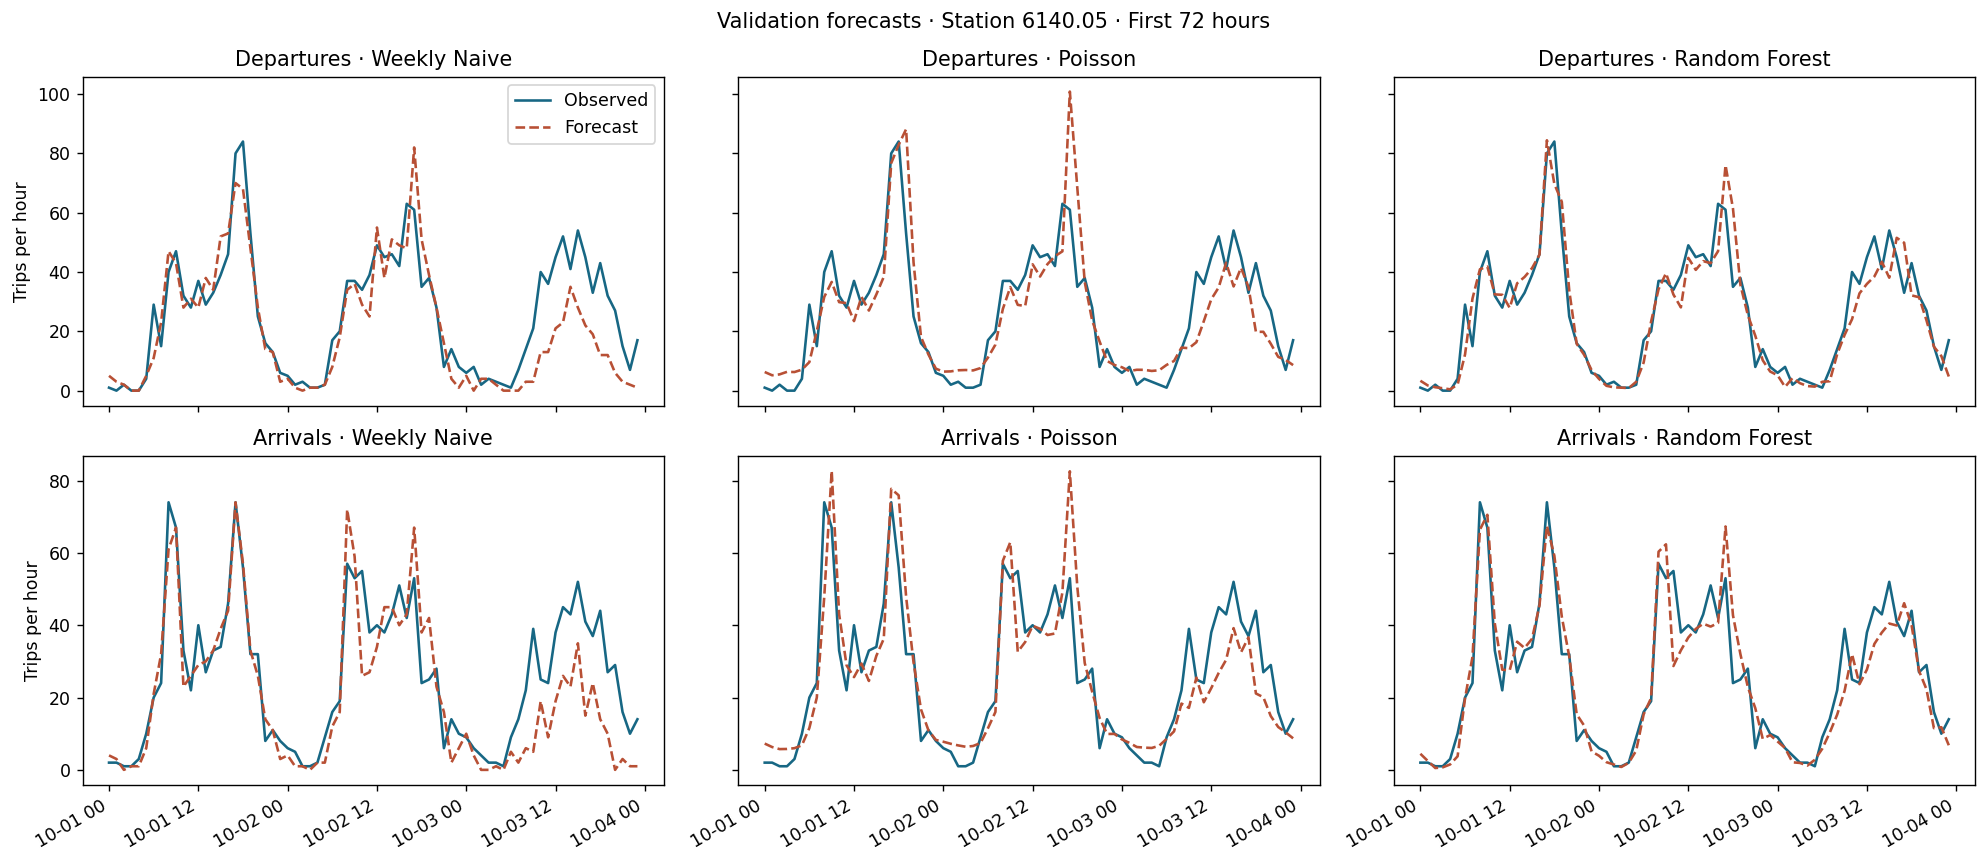

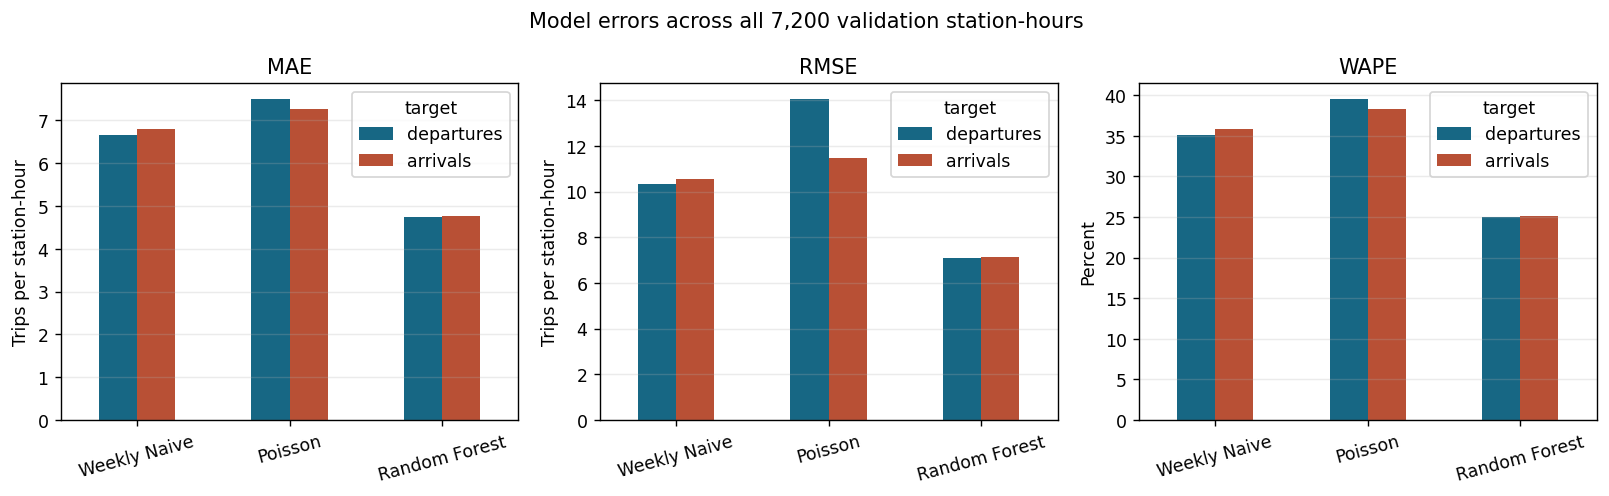

In [4]:
import matplotlib.pyplot as plt

# 按训练期借车量与还车量之和选站，避免根据验证图是否好看来挑站。
station = train.groupby("station_id")[["departures", "arrivals"]].sum().sum(axis=1).idxmax()
start = validation.hour.min()
# 固定展示验证期第一段 72 小时。按时间排序后，折线按正确顺序连接。
window = validation.loc[
    validation.station_id.eq(station)
    & validation.hour.lt(start + pd.Timedelta(hours=72))
].sort_values("hour")
assert len(window) == 72

model_labels = ["Weekly Naive", "Poisson", "Random Forest"]
targets = ["departures", "arrivals"]
# 上排借车，下排还车。每行共享纵轴，横轴也统一，便于横向比较模型。
fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex=True, sharey="row")
for row, target in enumerate(targets):
    for col, label in enumerate(model_labels):
        ax = axes[row, col]
        # 基线读取已经构造的 lag_168。另两个模型用已拟合的对象预测，绘图时无需再训练。
        if label == "Weekly Naive":
            predicted = window[f"{target}_lag_168"]
        else:
            predicted = fitted_models[target, label].predict(window[feature_columns[target]])
        # 蓝线是实际需求，橙色虚线是预测。两线在某个时点的高度差表示该小时的误差。
        ax.plot(window.hour, window[target], color="#176784", label="Observed")
        ax.plot(window.hour, predicted, color="#B85035", linestyle="--", label="Forecast")
        ax.set_title(f"{target.capitalize()} · {label}")
        if col == 0:
            ax.set_ylabel("Trips per hour")
axes[0, 0].legend()
fig.suptitle(f"Validation forecasts · Station {station} · First 72 hours")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

# 折线图只展示一个站点的案例。下面的柱状图汇总全部 7,200 条验证记录。
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, metric in zip(axes, ["MAE", "RMSE", "WAPE"]):
    # 把结果转成每个模型一行、借车和还车各一列，以便并排画柱。
    table = validation_scores.pivot(index="model", columns="target", values=metric)
    table.reindex(index=model_labels, columns=targets).plot.bar(ax=ax, rot=15, color=["#176784", "#B85035"])
    # MAE、RMSE 用辆／站点小时，WAPE 用百分比。三项指标都是越低越好。
    ax.set(title=metric, xlabel="", ylabel="Percent" if metric == "WAPE" else "Trips per station-hour")
    ax.grid(axis="y", alpha=.25)
fig.suptitle("Model errors across all 7,200 validation station-hours")
fig.tight_layout()
plt.show()


图中展示了训练期借还总量最高的站点（6140.05）在验证期前 72 小时的预测结果。周季节基线大致跟上了前两天的需求变化，但在 10 月 3 日明显低估了借车和还车需求。Poisson 回归在 10 月 2 日高估了部分峰值，其中借车峰值的预测超过每小时 100 单，实际为 60 多单。随机森林的预测曲线整体更贴近实际值，尤其是在第三天，但对个别短时峰值仍有偏差。这组图用于展示单站点的预测表现，模型的整体比较以全部 7,200 条验证记录上的误差指标为准。

## 5. 最终模型重训与测试
锁定验证集选出的随机森林和 11 个特征。合并 8 月 8 日至 10 月 15 日的记录重新拟合，在 10 月 16–31 日逐小时预测。测试期已观测的历史可用于下一小时的特征，模型参数在测试期固定。周季节基线用于对照。

In [5]:
from sklearn.base import clone

# 从头构造完整的过去特征，保留切分边界之前的历史。
full_features = create_demand_features(raw)
for target in feature_columns:
    grouped = full_features.groupby("station_id")[target]
    for lag in extra_lags:
        full_features[f"{target}_lag_{lag}"] = grouped.shift(lag)
full_features = remove_incomplete_history(full_features)
test_start = pd.Timestamp("2026-10-16")
test_end = pd.Timestamp("2026-11-01")
refit = full_features.loc[full_features.hour.lt(test_start)]
test = full_features.loc[full_features.hour.between(test_start, test_end, inclusive="left")]
assert (len(refit), len(test)) == (33120, 7680)
assert test.groupby("hour").station_id.nunique().eq(20).all()

# clone 复制已选模型的配置和预处理列，但不带入原先拟合的参数。
test_predictions = {}
test_scores = []
test_baseline = seasonal_naive_predictions(test)
for target, columns in feature_columns.items():
    label = selected_models[target]
    final_model = clone(fitted_models[target, label])
    final_model.fit(refit[columns], refit[target])
    test_predictions[target] = final_model.predict(test[columns])
    for name, prediction in [(label, test_predictions[target]),
                             ("Weekly Naive", test_baseline[f"predicted_{target}"])]:
        test_scores.append({"target": target, "model": name,
                            **evaluate_forecast(test[target].to_numpy(), prediction)})
display(pd.DataFrame(test_scores).round(3))

    target         model   MAE   RMSE   WAPE
departures Random Forest 4.618  7.049 25.185
departures  Weekly Naive 6.339 10.000 34.572
  arrivals Random Forest 4.573  6.827 24.947
  arrivals  Weekly Naive 6.231  9.888 33.987


target,model,MAE,RMSE,WAPE
departures,Random Forest,4.618,7.049,25.185
departures,Weekly Naive,6.339,10.000,34.572
arrivals,Random Forest,4.573,6.827,24.947
arrivals,Weekly Naive,6.231,9.888,33.987


## 6. 最终测试误差按小时分组
把测试期各站的绝对误差按一天中的 24 个小时取平均。曲线的高点对应更难预测的时段。

departures: largest MAE at 17:00 (9.41)
arrivals: largest MAE at 17:00 (8.22)


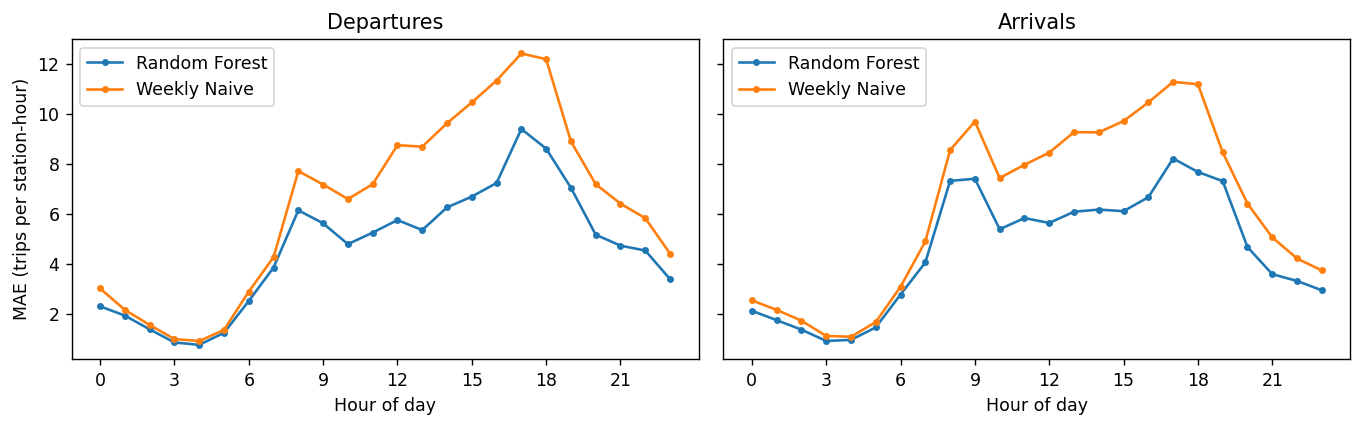

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, target in zip(axes, feature_columns):
    actual = test[target].to_numpy()
    for label, predicted in [
        (selected_models[target], test_predictions[target]),
        ("Weekly Naive", test_baseline[f"predicted_{target}"].to_numpy()),
    ]:
        absolute_error = pd.Series(abs(actual - predicted), index=test.index)
        hourly_mae = absolute_error.groupby(test.hour.dt.hour).mean()
        ax.plot(hourly_mae.index, hourly_mae, marker=".", label=label)
        if label == selected_models[target]:
            print(f"{target}: largest MAE at {hourly_mae.idxmax():02}:00 ({hourly_mae.max():.2f})")
    ax.set(title=target.capitalize(), xlabel="Hour of day", xticks=range(0, 24, 3))
    ax.legend()
axes[0].set_ylabel("MAE (trips per station-hour)")
fig.tight_layout()
plt.show()

## 7. 站点失衡优先级
预测净流量为预测还车量减预测借车量，每小时按绝对值给 20 个站点排名。固定展示测试期最后一小时，蓝色为预测净流入，橙色为预测净流出，黑点为实际净流量。实际缺车或满桩还取决于当时的库存与容量。

 priority_rank station_id  predicted_net_flow  actual_net_flow
             1    6364.07              -12.01                2
             2     5980.1              -10.72               -2
             3    6726.01                6.07                8
             4    6072.06                5.44              -10
             5     6948.1               -5.34               -2


priority_rank,station_id,predicted_net_flow,actual_net_flow
1,6364.07,-12.01,2
2,5980.1,-10.72,-2
3,6726.01,6.07,8
4,6072.06,5.44,-10
5,6948.1,-5.34,-2


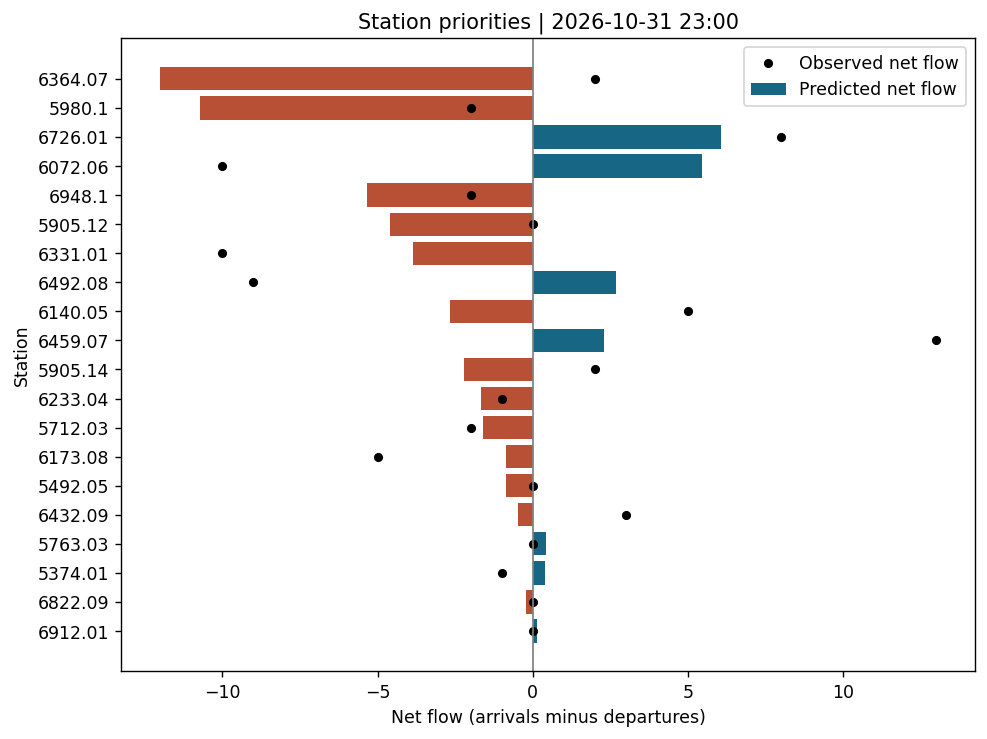

In [7]:
from rebalancing import create_rebalancing_priorities

priorities = create_rebalancing_priorities(
    test, test_predictions["departures"], test_predictions["arrivals"]
)
priorities["actual_net_flow"] = priorities.arrivals - priorities.departures
example_hour = test.hour.max()
example = priorities.loc[priorities.hour.eq(example_hour)]
columns = ["priority_rank", "station_id", "predicted_net_flow", "actual_net_flow"]
display(example[columns].head(5).round(2))

plot_data = example.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
colors = ["#176784" if value >= 0 else "#B85035" for value in plot_data.predicted_net_flow]
ax.barh(plot_data.station_id, plot_data.predicted_net_flow, color=colors, label="Predicted net flow")
ax.scatter(plot_data.actual_net_flow, plot_data.station_id, color="black", s=18, label="Observed net flow")
ax.axvline(0, color="gray", linewidth=1)
ax.set(title=f"Station priorities | {example_hour:%Y-%m-%d %H:%M}",
       xlabel="Net flow (arrivals minus departures)", ylabel="Station")
ax.legend()
fig.tight_layout()
plt.show()